In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import financepy
import openpyxl
from financepy.utils.date import Date
from financepy.utils.day_count import DayCountTypes
from financepy.utils.frequency import FrequencyTypes
from financepy.utils.calendar import CalendarTypes, BusDayAdjustTypes, DateGenRuleTypes
from financepy.utils.global_types import SwapTypes
from financepy.products.rates.ois import OIS
from financepy.products.rates.ois_curve import OISCurve
from financepy.market.curves.interpolator import InterpTypes
import datetime as dt
from tqdm import tqdm
from financepy.products.bonds.bond import Bond
from scipy.optimize import least_squares

In [2]:
TICKER_TENOR = {
    "BPSWS1Z":  ("WK",  1),
    "BPSWS2Z":  ("WK",  2),
    "BPSWSA":   ("MO",  1),
    "BPSWSB":   ("MO",  2),
    "BPSWSC":   ("MO",  3),
    "BPSWSD":   ("MO",  4),
    "BPSWSE":   ("MO",  5),
    "BPSWSF":   ("MO",  6),
    "BPSWSG":   ("MO",  7),
    "BPSWSH":   ("MO",  8),
    "BPSWSI":   ("MO",  9),
    "BPSWSJ":   ("MO", 10),
    "BPSWSK":   ("MO", 11),
    "BPSWS1":   ("YR",  1),
    "BPSWS1F":  ("MO", 18),
    "BPSWS2":   ("YR",  2),
    "BPSWS3":   ("YR",  3),
    "BPSWS4":   ("YR",  4),
    "BPSWS5":   ("YR",  5),
    "BPSWS6":   ("YR",  6),
    "BPSWS7":   ("YR",  7),
    "BPSWS8":   ("YR",  8),
    "BPSWS9":   ("YR",  9),
    "BPSWS10":  ("YR", 10),
    "BPSWS12":  ("YR", 12),
    "BPSWS15":  ("YR", 15),
    "BPSWS20":  ("YR", 20),
    "BPSWS25":  ("YR", 25),
    "BPSWS30":  ("YR", 30),
    "BPSWS40":  ("YR", 40),
    "BPSWS50":  ("YR", 50),
}

In [3]:
def load_swap_rates(xlsx_path, valuation_date):
    
    target_date = valuation_date.date() if hasattr(valuation_date, "date") else valuation_date

    wb = openpyxl.load_workbook(xlsx_path, data_only=True)
    ws = wb["gbp ois results"]

    header = [c.value for c in ws[1]]
    rates = {}


    for col_idx in range(1, ws.max_column + 1, 2):
        ticker_full = header[col_idx]
        if not ticker_full or "Curncy" not in str(ticker_full):
            continue
        ticker = ticker_full.replace(" Curncy", "")

        
        for row in range(2, ws.max_row + 1):
            d = ws.cell(row, col_idx).value
            d = d.date() if hasattr(d, "date") else d
            v = ws.cell(row, col_idx + 1).value
            if d == target_date and v is not None:
                rates[ticker] = float(v) / 100.0
                break

    return rates

In [4]:
def build_sonia_curve(valuation_date_py, rates_dict):
    
    val_dt = Date(valuation_date_py.day, valuation_date_py.month, valuation_date_py.year)
 
    cal_type   = CalendarTypes.UNITED_KINGDOM
    bus_adj    = BusDayAdjustTypes.MODIFIED_FOLLOWING
    dg_rule    = DateGenRuleTypes.BACKWARD
    fix_freq   = FrequencyTypes.ANNUAL
    fix_dcc    = DayCountTypes.ACT_365F
    float_freq = FrequencyTypes.ANNUAL
    float_dcc  = DayCountTypes.ACT_365F
    pay_or_rec = SwapTypes.PAY
 
    settle_dt = val_dt
 
    swaps = []
    for ticker, rate in rates_dict.items():
        unit, n = TICKER_TENOR[ticker]
        if unit == "WK":
            tenor_str = f"{n}W"
        elif unit == "MO":
            tenor_str = f"{n}M"
        elif unit == "YR":
            tenor_str = f"{n}Y"
 
        ois = OIS(
            effective_dt = settle_dt,
            term_dt_or_tenor = tenor_str,
            fixed_leg_type = pay_or_rec,
            fixed_cpn = rate,
            fixed_freq_type = fix_freq,
            fixed_dc_type = fix_dcc,
            notional = 1_000_000,
            payment_lag = 0,
            float_freq_type = float_freq,
            float_dc_type = float_dcc,
            cal_type = cal_type,
            bd_type = bus_adj,
            dg_type = dg_rule,
        )
        swaps.append(ois)
 
 
    curve = OISCurve(
        value_dt = val_dt,
        ois_deposits = [],
        ois_fras = [],
        ois_swaps = swaps,
        interp_type = InterpTypes.FLAT_FWD_RATES,
    )
    
    return curve

In [5]:
if __name__ == "__main__":
    import datetime as dt
 
    XLSX = "/Users/ze/Desktop/Bloomberg - Historical Data v2026-01-21.xlsx"
    VALUATION_DATE = dt.datetime(2023, 1, 30)
 
    
    rates = load_swap_rates(XLSX, VALUATION_DATE)
    print(f"Loaded {len(rates)} swap rates for {VALUATION_DATE.date()}")
    for k, v in list(rates.items())[:5]:
        print(f"  {k:10s}  {v*100:6.4f}%")
 
    
    curve = build_sonia_curve(VALUATION_DATE.date(), rates)
 
    
    val_dt = Date(VALUATION_DATE.day, VALUATION_DATE.month, VALUATION_DATE.year)
    for tenor in ["1M", "1Y", "5Y", "10Y", "30Y"]:
        T = val_dt.add_tenor(tenor)
        df = curve.df(T)
        years = (T - val_dt) / 365.0
        zero = 100 * ((1.0 / df) ** (1.0 / years) - 1.0) if years > 0 else 0
        print(f"  T={tenor:4s}  P(t,T)={df:.6f}  annual zero ~{zero:.3f}%")

Loaded 29 swap rates for 2023-01-30
  BPSWS1Z     3.6888%
  BPSWS2Z     3.7874%
  BPSWSA      3.8407%
  BPSWSB      3.9061%
  BPSWSE      4.1595%
  T=1M    P(t,T)=0.996958  annual zero ~3.909%
  T=1Y    P(t,T)=0.958474  annual zero ~4.332%
  T=5Y    P(t,T)=0.837938  annual zero ~3.597%
  T=10Y   P(t,T)=0.718920  annual zero ~3.352%
  T=30Y   P(t,T)=0.398189  annual zero ~3.115%


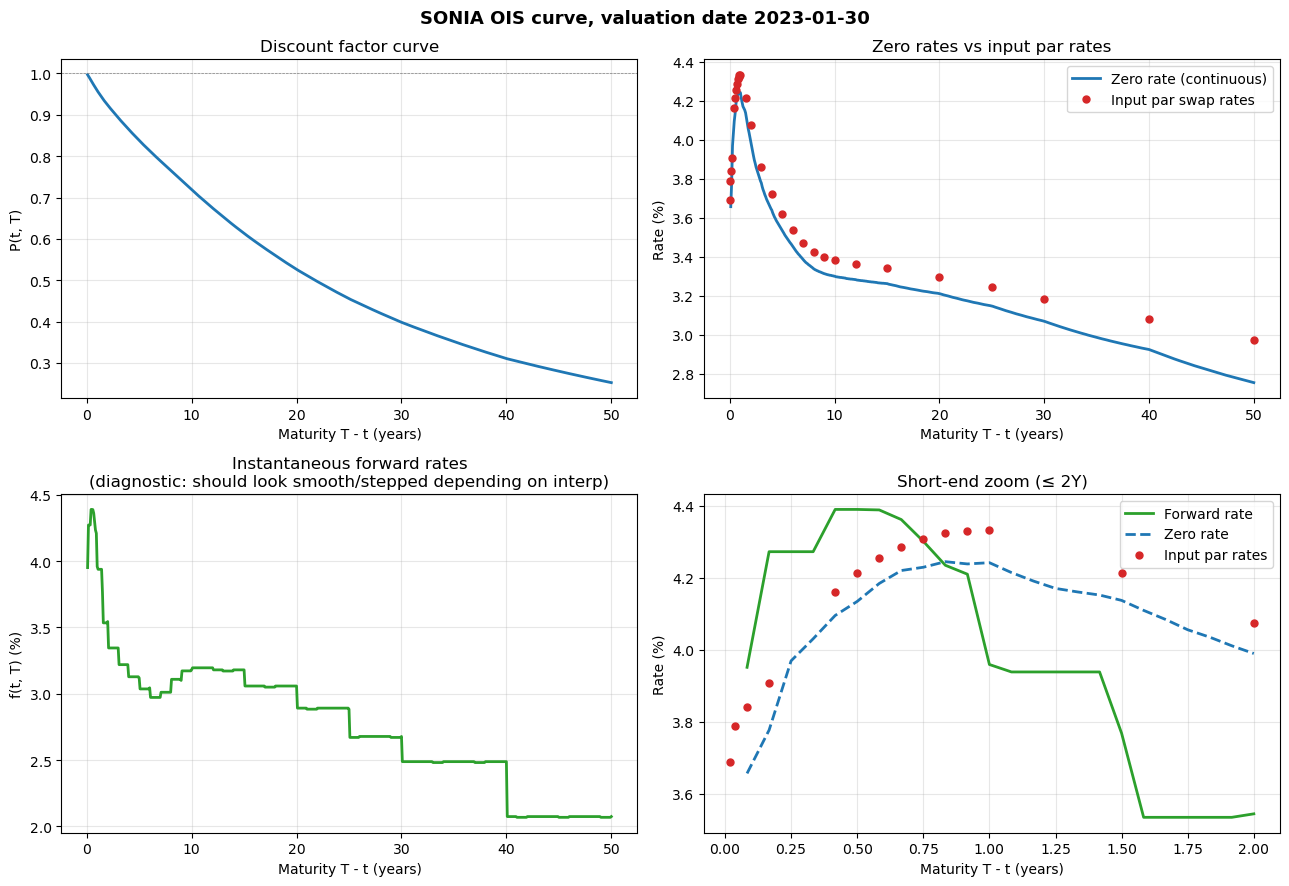

In [6]:
val_dt = Date(VALUATION_DATE.day, VALUATION_DATE.month, VALUATION_DATE.year)


years_grid = np.linspace(1/12, 50, 600)


plot_dates = [val_dt.add_years(float(y)) for y in years_grid]


discount_factors = np.array([curve.df(d) for d in plot_dates])


zero_rates = -np.log(discount_factors) / years_grid


log_df = np.log(discount_factors)
fwd_rates = np.array([curve.fwd(d) for d in plot_dates])


input_tenors = []   # in years
input_rates = []
for ticker, rate in rates.items():
    unit, n = TICKER_TENOR[ticker]
    if unit == "WK":
        yrs = n * 7 / 365
    elif unit == "MO":
        yrs = n / 12
    else:
        yrs = n
    input_tenors.append(yrs)
    input_rates.append(rate * 100)
order = np.argsort(input_tenors)
input_tenors = np.array(input_tenors)[order]
input_rates = np.array(input_rates)[order]



fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) Discount factor curve
ax = axes[0, 0]
ax.plot(years_grid, discount_factors, lw=2, color="C0")
ax.set_xlabel("Maturity T - t (years)")
ax.set_ylabel("P(t, T)")
ax.set_title("Discount factor curve")
ax.grid(alpha=0.3)
ax.axhline(1.0, color="grey", lw=0.5, ls="--")

# (b) Zero rates with par swap rates overlaid
ax = axes[0, 1]
ax.plot(years_grid, zero_rates * 100, lw=2, color="C0", label="Zero rate (continuous)")
ax.plot(input_tenors, input_rates, "o", color="C3", markersize=5, label="Input par swap rates")
ax.set_xlabel("Maturity T - t (years)")
ax.set_ylabel("Rate (%)")
ax.set_title("Zero rates vs input par rates")
ax.grid(alpha=0.3)
ax.legend()

# (c) Instantaneous forward rates
ax = axes[1, 0]
ax.plot(years_grid, fwd_rates * 100, lw=2, color="C2")
ax.set_xlabel("Maturity T - t (years)")
ax.set_ylabel("f(t, T) (%)")
ax.set_title("Instantaneous forward rates\n(diagnostic: should look smooth/stepped depending on interp)")
ax.grid(alpha=0.3)

# (d) Zoom on short end (0 to 2 years) to see Bank of England policy shape
ax = axes[1, 1]
mask = years_grid <= 2
ax.plot(years_grid[mask], fwd_rates[mask] * 100, lw=2, color="C2", label="Forward rate")
ax.plot(years_grid[mask], zero_rates[mask] * 100, lw=2, color="C0", ls="--", label="Zero rate")
short_inputs = input_tenors <= 2
ax.plot(input_tenors[short_inputs], input_rates[short_inputs], "o",
        color="C3", markersize=5, label="Input par rates")
ax.set_xlabel("Maturity T - t (years)")
ax.set_ylabel("Rate (%)")
ax.set_title("Short-end zoom (≤ 2Y)")
ax.grid(alpha=0.3)
ax.legend()

plt.suptitle(f"SONIA OIS curve, valuation date {VALUATION_DATE.date()}",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
def load_all_swap_rates(xlsx_path):
    
    wb = openpyxl.load_workbook(xlsx_path, data_only=True)
    ws = wb["gbp ois results"]
 
    header = [c.value for c in ws[1]]
 
    # Collect data per ticker
    series_dict = {}
    for col_idx in range(1, ws.max_column + 1, 2):
        ticker_full = header[col_idx]
        if not ticker_full or "Curncy" not in str(ticker_full):
            continue
        ticker = ticker_full.replace(" Curncy", "")
 
        dates, vals = [], []
        for row in range(2, ws.max_row + 1):
            d = ws.cell(row, col_idx).value
            v = ws.cell(row, col_idx + 1).value
            if d is None or v is None:
                continue
            
            if isinstance(d, dt.datetime):
                d = d.date()
            elif isinstance(d, (int, float)):
                d = (dt.datetime(1899, 12, 30) + dt.timedelta(days=int(d))).date()
            dates.append(d)
            vals.append(float(v) / 100.0)   # % -> decimal
 
        series_dict[ticker] = pd.Series(vals, index=dates)
 
    df = pd.DataFrame(series_dict).sort_index()
    return df

In [8]:
def build_all_curves(rates_df):
    
    curves = {}
    failed = []
 
    for valuation_date in tqdm(rates_df.index, desc="Building curves"):
        row = rates_df.loc[valuation_date].dropna()
        rates_dict = row.to_dict()
 
        if len(rates_dict) < 10:
            # too few quotes to build a meaningful curve
            failed.append((valuation_date, "too few quotes"))
            continue
 
        try:
            curve = build_sonia_curve(valuation_date, rates_dict)
            curves[valuation_date] = curve
        except Exception as e:
            failed.append((valuation_date, str(e)[:80]))
 
    return curves, failed

In [9]:
XLSX = "/Users/ze/Desktop/Bloomberg - Historical Data v2026-01-21.xlsx"
 
print("Loading rates from Excel...")
rates_df = load_all_swap_rates(XLSX)
print(f"  Shape: {rates_df.shape}  (dates x tickers)")
print(f"  Date range: {rates_df.index.min()} to {rates_df.index.max()}")
print(f"  Tickers: {list(rates_df.columns)[:5]} ... ({len(rates_df.columns)} total)")
 
print("\nBuilding curves...")
curves, failed = build_all_curves(rates_df)
print(f"\n  Built {len(curves)} curves")
print(f"  Failed: {len(failed)}")
if failed[:3]:
    print("  First few failures:")
    for d, msg in failed[:3]:
        print(f"    {d}: {msg}")

Loading rates from Excel...
  Shape: (766, 29)  (dates x tickers)
  Date range: 2023-01-30 to 2026-01-21
  Tickers: ['BPSWS1Z', 'BPSWS2Z', 'BPSWSA', 'BPSWSB', 'BPSWSE'] ... (29 total)

Building curves...


Building curves: 100%|██████████| 766/766 [00:21<00:00, 35.29it/s]


  Built 753 curves
  Failed: 13
  First few failures:
    2023-04-07: too few quotes
    2023-05-08: too few quotes
    2023-05-29: too few quotes


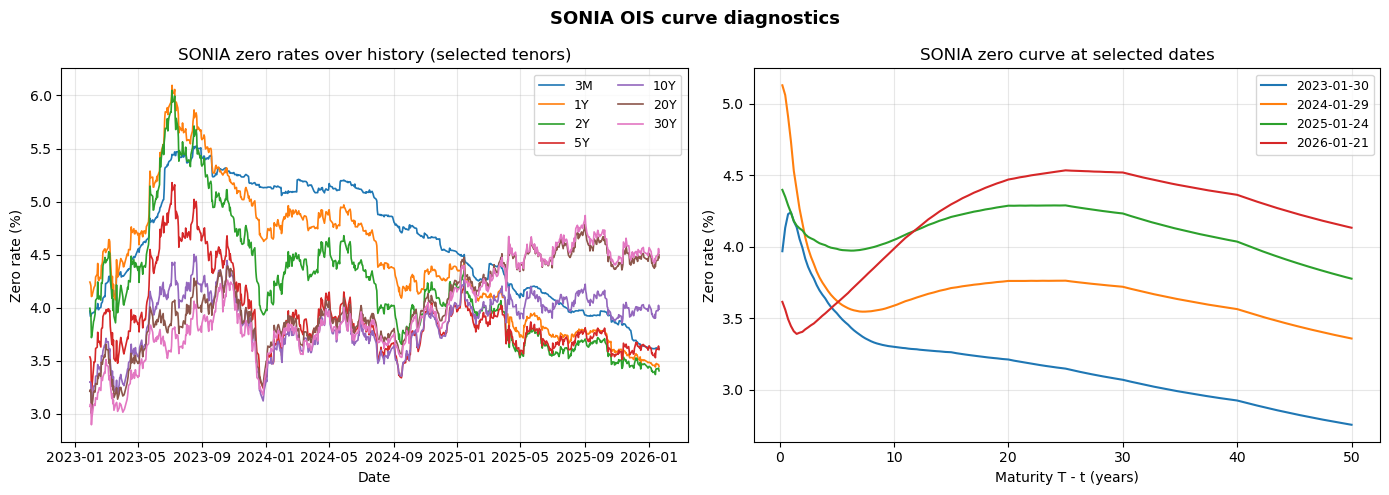

In [10]:
tenors_to_track = [0.25, 1, 2, 5, 10, 20, 30]
tenor_labels    = ["3M", "1Y", "2Y", "5Y", "10Y", "20Y", "30Y"]

dates_list = sorted(curves.keys())
zero_history = {lbl: [] for lbl in tenor_labels}

for d in dates_list:
    val_dt = Date(d.day, d.month, d.year)
    for yrs, lbl in zip(tenors_to_track, tenor_labels):
        T = val_dt.add_years(float(yrs))
        df_val = curves[d].df(T)
        z = -np.log(df_val) / yrs
        zero_history[lbl].append(z * 100)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: time series of zero rates
ax = axes[0]
for lbl in tenor_labels:
    ax.plot(dates_list, zero_history[lbl], label=lbl, lw=1.2)
ax.set_xlabel("Date")
ax.set_ylabel("Zero rate (%)")
ax.set_title("SONIA zero rates over history (selected tenors)")
ax.legend(loc="best", ncol=2, fontsize=9)
ax.grid(alpha=0.3)

# Right: a few representative full curves
sample_idxs = [0, len(dates_list)//3, 2*len(dates_list)//3, len(dates_list)-1]
sample_dates = [dates_list[i] for i in sample_idxs]

ax = axes[1]
years_grid = np.linspace(0.25, 50, 200)
for d in sample_dates:
    val_dt = Date(d.day, d.month, d.year)
    dfs = np.array([curves[d].df(val_dt.add_years(float(y))) for y in years_grid])
    zeros = -np.log(dfs) / years_grid * 100
    ax.plot(years_grid, zeros, lw=1.5, label=str(d))

ax.set_xlabel("Maturity T - t (years)")
ax.set_ylabel("Zero rate (%)")
ax.set_title("SONIA zero curve at selected dates")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)

plt.suptitle("SONIA OIS curve diagnostics", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


In [11]:
print(f"Curves built: {len(curves)}")
print(f"Date range:   {dates_list[0]}  to  {dates_list[-1]}")
print()
print("Zero rate summary (across history):")
print(f"{'Tenor':<6}  {'min%':>7}  {'mean%':>7}  {'max%':>7}")
for lbl in tenor_labels:
    arr = np.array(zero_history[lbl])
    print(f"{lbl:<6}  {arr.min():>7.3f}  {arr.mean():>7.3f}  {arr.max():>7.3f}")

Curves built: 753
Date range:   2023-01-30  to  2026-01-21

Zero rate summary (across history):
Tenor      min%    mean%     max%
3M        3.614    4.629    5.525
1Y        3.441    4.468    6.096
2Y        3.370    4.218    6.048
5Y        3.196    3.904    5.178
10Y       3.010    3.876    4.502
20Y       3.003    4.046    4.789
30Y       2.897    3.984    4.869


In [12]:
GILTS_XLSX = "/Users/ze/Desktop/Gilts_Historical_Data_2020_2025.xlsx"

In [13]:
def load_gilt_static(xlsx_path):
    
    wb = openpyxl.load_workbook(xlsx_path, data_only=True)
    ws = wb["STATIC"]
    out = {}
    for row in ws.iter_rows(min_row=2, values_only=True):
        isin, _, _, descr, mat, cpn, fcd, fsd = row
        if isin is None:
            continue
        out[isin] = {
            "description": descr,
            "maturity_date": mat.date() if hasattr(mat, "date") else mat,
            "coupon": float(cpn),
            "first_coupon_date": fcd.date() if hasattr(fcd, "date") else fcd,
            "settle_date": fsd.date() if hasattr(fsd, "date") else fsd,
        }
    return out

In [14]:
def load_gilt_prices(xlsx_path):
    
    import pandas as pd
    wb = openpyxl.load_workbook(xlsx_path, data_only=True)
    ws = wb["HIST_PRICE"]
 
    header = [c.value for c in ws[1]]
    isins = header[1:]
 
    rows = []
    for row in ws.iter_rows(min_row=2, values_only=True):
        date_val = row[0]
        if date_val is None:
            continue
        if hasattr(date_val, "date"):
            date_val = date_val.date()
        rows.append([date_val] + list(row[1:]))
 
    df = pd.DataFrame(rows, columns=["date"] + isins).set_index("date")
    return df

In [15]:
def make_bond(static_info):
    
    issue   = static_info["settle_date"]
    mat     = static_info["maturity_date"]
    cpn     = static_info["coupon"]
 
    issue_dt = Date(issue.day, issue.month, issue.year)
    mat_dt   = Date(mat.day, mat.month, mat.year)
 
    bond = Bond(
        issue_dt    = issue_dt,
        maturity_dt = mat_dt,
        coupon      = cpn,
        freq_type   = FrequencyTypes.SEMI_ANNUAL,    # Gilts pay semi-annually
        dc_type     = DayCountTypes.ACT_ACT_ICMA,    # Gilt convention
    )
    return bond

In [16]:
def compute_zspread(bond, clean_price, valuation_date_py, sonia_curve):
    
    val_dt = Date(valuation_date_py.day, valuation_date_py.month, valuation_date_py.year)
 
    
    clean_price_100 = clean_price * 100.0
 
    z = bond.z_spread(val_dt, clean_price_100, sonia_curve)
    return z

In [17]:
print("Loading Gilt static data...")
static = load_gilt_static(GILTS_XLSX)
print(f"  {len(static)} bonds in STATIC")
 
print("Loading Gilt prices...")
prices = load_gilt_prices(GILTS_XLSX)
print(f"  Price table shape: {prices.shape}")
 

TEST_DATE = dt.date(2023, 1, 30)
assert TEST_DATE in curves, f"No SONIA curve for {TEST_DATE}"
assert TEST_DATE in prices.index, f"No prices for {TEST_DATE}"
 

ALIVE_BONDS = [isin for isin, info in static.items()
               if info["maturity_date"] > TEST_DATE
               and isin in prices.columns
               and prices.loc[TEST_DATE, isin] is not None]
print(f"  {len(ALIVE_BONDS)} bonds alive on {TEST_DATE}")

Loading Gilt static data...
  98 bonds in STATIC
Loading Gilt prices...
  Price table shape: (1312, 80)
  79 bonds alive on 2023-01-30


In [18]:
EST_ISIN = None
for isin in ALIVE_BONDS:
    info = static[isin]
    yrs_to_mat = (info["maturity_date"] - TEST_DATE).days / 365.25
    if 5 < yrs_to_mat < 10:
        TEST_ISIN = isin
        break
 
print(f"\nTest bond: {TEST_ISIN}")
info = static[TEST_ISIN]
print(f"  Description : {info['description']}")
print(f"  Coupon      : {info['coupon']*100:.3f}%")
print(f"  Maturity    : {info['maturity_date']}")
print(f"  Issue       : {info['settle_date']}")
print(f"  Clean price : {prices.loc[TEST_DATE, TEST_ISIN]} (per £1 face)")
 

bond = make_bond(info)
clean_price = prices.loc[TEST_DATE, TEST_ISIN]
sonia_curve = curves[TEST_DATE]
 
z = compute_zspread(bond, clean_price, TEST_DATE, sonia_curve)
print(f"\n  Z-spread = {z*10000:.2f} bp")


Test bond: GB00BMBL1G81
  Description : UKT 0.125 31/01/28
  Coupon      : 0.125%
  Maturity    : 2028-01-31
  Issue       : 2020-06-12
  Clean price : 0.85715 (per £1 face)

  Z-spread = -32.15 bp


In [19]:
val_dt = Date(TEST_DATE.day, TEST_DATE.month, TEST_DATE.year)

# Price the bond off the SONIA curve directly (no spread)
clean_from_curve = bond.clean_price_from_discount_curve(val_dt, sonia_curve)
dirty_from_curve = bond.dirty_price_from_discount_curve(val_dt, sonia_curve)
print(f"Model clean price (z=0): {clean_from_curve}")
print(f"Model dirty price (z=0): {dirty_from_curve}")
print(f"Market clean price:      {clean_price} (per £1)  =  {clean_price*100} (per £100)")


Model clean price (z=0): 84.35156042371699
Model dirty price (z=0): 84.41372074980394
Market clean price:      0.85715 (per £1)  =  85.715 (per £100)


In [20]:
for isin in ALIVE_BONDS:
    info = static[isin]
    yrs_to_mat = (info["maturity_date"] - TEST_DATE).days / 365.25
    if 5 < yrs_to_mat < 10 and info["coupon"] > 0.03:
        cp2 = prices.loc[TEST_DATE, isin]
        print(f"Trying: {isin}  cpn={info['coupon']*100:.2f}%  "
              f"mat={info['maturity_date']}  price={cp2:.5f}")
        break

Trying: GB00BSQNRC93  cpn=4.38%  mat=2028-03-07  price=nan


In [21]:
for isin in ALIVE_BONDS:
    info = static[isin]
    yrs_to_mat = (info["maturity_date"] - TEST_DATE).days / 365.25
    if 5 < yrs_to_mat < 10 and info["coupon"] > 0.03:
        cp2 = prices.loc[TEST_DATE, isin]
        if cp2 is None or (isinstance(cp2, float) and np.isnan(cp2)):
            continue   # skip bonds with missing prices
        bond2 = make_bond(info)
        z2 = compute_zspread(bond2, cp2, TEST_DATE, curves[TEST_DATE])
        print(f"{isin}: cpn={info['coupon']*100:.2f}%, mat={info['maturity_date']}, "
              f"price={cp2:.4f}, z={z2*10000:.2f} bp")
        break

GB0002404191: cpn=6.00%, mat=2028-12-07, price=1.1413, z=-20.59 bp


Computed z-spreads for 60 bonds on 2023-01-30
Failures: 0


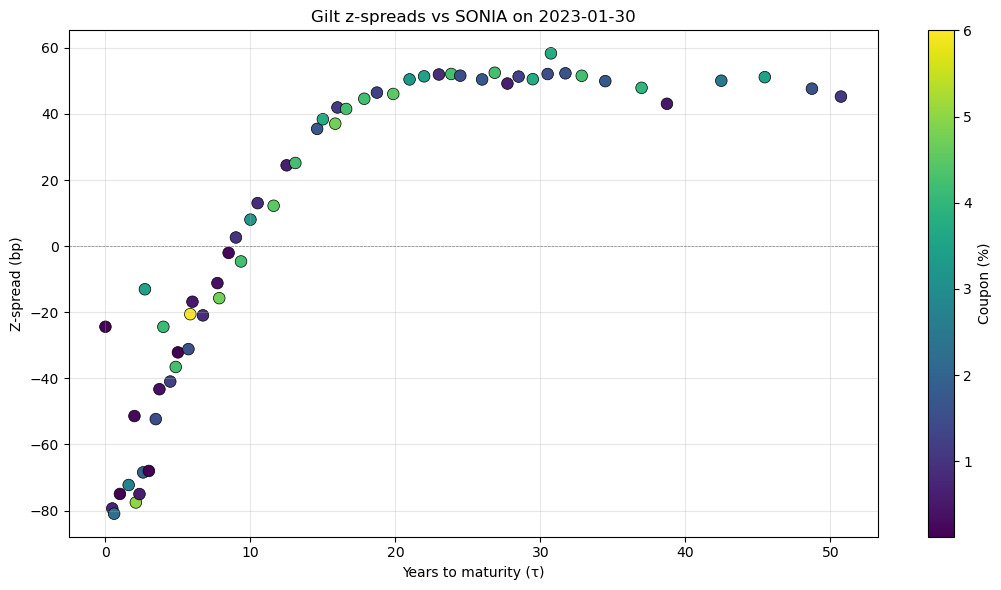


Z-spread cross-section summary (bp):
  min    : -80.96
  median : 24.80
  mean   : 7.31
  max    : 58.33
  std    : 45.80


In [22]:
def is_alive_with_price(isin, date):
    if isin not in static or isin not in prices.columns:
        return False
    if static[isin]["maturity_date"] <= date:
        return False
    p = prices.loc[date, isin]
    if p is None:
        return False
    if isinstance(p, float) and np.isnan(p):
        return False
    return True


def zspreads_one_date(date):
    
    sonia_curve = curves[date]
    alive = [isin for isin in static if is_alive_with_price(isin, date)]

    out = {}
    failed = []
    for isin in alive:
        info = static[isin]
        clean_price = prices.loc[date, isin]
        try:
            bond = make_bond(info)
            z = compute_zspread(bond, clean_price, date, sonia_curve)
            tau = (info["maturity_date"] - date).days / 365.25
            out[isin] = {
                "tau": tau,
                "z": z,
                "coupon": info["coupon"],
                "description": info["description"],
            }
        except Exception as e:
            failed.append((isin, str(e)[:60]))
    return out, failed



zs, failures = zspreads_one_date(TEST_DATE)
print(f"Computed z-spreads for {len(zs)} bonds on {TEST_DATE}")
print(f"Failures: {len(failures)}")
for isin, msg in failures[:5]:
    print(f"  {isin}: {msg}")


isins  = list(zs.keys())
taus   = np.array([zs[i]["tau"]    for i in isins])
zspr   = np.array([zs[i]["z"]*1e4  for i in isins])   # to bp
cpns   = np.array([zs[i]["coupon"]*100 for i in isins])

# ---- Plot: z-spread cross-section -----------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(taus, zspr, c=cpns, cmap="viridis", s=70, edgecolor="k", lw=0.5)
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel("Years to maturity (τ)")
ax.set_ylabel("Z-spread (bp)")
ax.set_title(f"Gilt z-spreads vs SONIA on {TEST_DATE}")
ax.grid(alpha=0.3)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Coupon (%)")
plt.tight_layout()
plt.show()


print(f"\nZ-spread cross-section summary (bp):")
print(f"  min    : {zspr.min():.2f}")
print(f"  median : {np.median(zspr):.2f}")
print(f"  mean   : {zspr.mean():.2f}")
print(f"  max    : {zspr.max():.2f}")
print(f"  std    : {zspr.std():.2f}")


In [23]:
print("Building Bond objects...")
bond_objects = {}
for isin, info in static.items():
    try:
        bond_objects[isin] = make_bond(info)
    except Exception as e:
        print(f"  Could not build {isin}: {e}")
print(f"  Built {len(bond_objects)} bond objects")

Building Bond objects...
  Built 98 bond objects


In [24]:
date_list = sorted(curves.keys())
print(f"\nProcessing {len(date_list)} dates...")


Processing 753 dates...


In [25]:
z_data = {}
fail_log = []
 
for date in tqdm(date_list, desc="Z-spreads"):
    sonia_curve = curves[date]
    z_today = {}
 
    # Pre-filter alive+priced bonds for this date
    if date not in prices.index:
        continue
    price_row = prices.loc[date]
 
    for isin, bond in bond_objects.items():
        # Skip if matured
        if static[isin]["maturity_date"] <= date:
            continue
        # Skip if no price
        if isin not in price_row.index:
            continue
        cp = price_row[isin]
        if cp is None or (isinstance(cp, float) and np.isnan(cp)):
            continue
        try:
            z = compute_zspread(bond, cp, date, sonia_curve)
            z_today[isin] = z
        except Exception as e:
            fail_log.append((date, isin, str(e)[:60]))
 
    z_data[date] = z_today

Z-spreads: 100%|██████████| 753/753 [03:57<00:00,  3.17it/s]


In [26]:
z_spreads = pd.DataFrame.from_dict(z_data, orient="index")
z_spreads.index.name = "date"
z_spreads = z_spreads.sort_index()
 
print(f"\nResult shape: {z_spreads.shape}  (dates x bonds)")
print(f"Total z-spreads computed: {z_spreads.notna().sum().sum():,}")
print(f"Failures: {len(fail_log)}")
if fail_log[:5]:
    print("First few failures:")
    for d, isin, msg in fail_log[:5]:
        print(f"  {d} {isin}: {msg}")


Result shape: (752, 79)  (dates x bonds)
Total z-spreads computed: 47,988
Failures: 0


In [27]:
print("\nZ-spread distribution (across all dates and bonds, in bp):")
all_z = z_spreads.values.flatten() * 1e4
all_z = all_z[~np.isnan(all_z)]
print(f"  count  : {len(all_z):,}")
print(f"  min    : {all_z.min():.1f}")
print(f"  median : {np.median(all_z):.1f}")
print(f"  mean   : {all_z.mean():.1f}")
print(f"  max    : {all_z.max():.1f}")
print(f"  std    : {all_z.std():.1f}")
 
 

z_spreads.to_pickle("/Users/ze/Desktop/z_spreads.pkl")
z_spreads.to_csv("/Users/ze/Desktop/z_spreads.csv")
print("\nSaved to z_spreads.pkl and z_spreads.csv on Desktop")


Z-spread distribution (across all dates and bonds, in bp):
  count  : 47,988
  min    : -310.1
  median : 48.5
  mean   : 36.6
  max    : 387.5
  std    : 38.7

Saved to z_spreads.pkl and z_spreads.csv on Desktop


In [28]:
MIN_TENOR_YEARS = 1.0
MAX_TENOR_YEARS = 50.0


def build_tau_matrix(z_spreads, static):
    """DataFrame same shape as z_spreads with years-to-maturity in each cell."""
    tau = pd.DataFrame(index=z_spreads.index, columns=z_spreads.columns, dtype=float)
    for isin in z_spreads.columns:
        if isin not in static:
            continue
        mat = static[isin]["maturity_date"]
        days = np.array([(mat - d).days for d in z_spreads.index])
        tau[isin] = days / 365.25
    return tau


print("Building tau matrix...")
tau = build_tau_matrix(z_spreads, static)

keep_mask = (tau >= MIN_TENOR_YEARS) & (tau <= MAX_TENOR_YEARS)
z_filtered = z_spreads.where(keep_mask)

n_before = z_spreads.notna().sum().sum()
n_after = z_filtered.notna().sum().sum()
print(f"Z-spreads before filter: {n_before:,}")
print(f"Z-spreads after  filter: {n_after:,}  (dropped {n_before - n_after:,})")

all_z = z_filtered.values.flatten() * 1e4
all_z = all_z[~np.isnan(all_z)]
print(f"\nFiltered z-spread distribution (bp):")
print(f"  count  : {len(all_z):,}")
print(f"  min    : {all_z.min():.1f}")
print(f"  median : {np.median(all_z):.1f}")
print(f"  mean   : {all_z.mean():.1f}")
print(f"  max    : {all_z.max():.1f}")
print(f"  std    : {all_z.std():.1f}")

daily_count = z_filtered.notna().sum(axis=1)
print(f"\nBonds usable per day:")
print(f"  min    : {daily_count.min()}  (on {daily_count.idxmin()})")
print(f"  median : {int(daily_count.median())}")
print(f"  max    : {daily_count.max()}  (on {daily_count.idxmax()})")

z_filtered.to_pickle("/Users/ze/Desktop/z_spreads_filtered.pkl")
print("\nSaved to z_spreads_filtered.pkl")


Building tau matrix...
Z-spreads before filter: 47,988
Z-spreads after  filter: 45,331  (dropped 2,657)

Filtered z-spread distribution (bp):
  count  : 45,331
  min    : -78.0
  median : 50.9
  mean   : 40.1
  max    : 107.0
  std    : 35.8

Bonds usable per day:
  min    : 55  (on 2023-01-31)
  median : 61
  max    : 66  (on 2025-10-29)

Saved to z_spreads_filtered.pkl


In [29]:
zb = z_filtered * 1e4

In [30]:
def yrs_to_mat(isin, on_date):
    return (static[isin]["maturity_date"] - on_date).days / 365.25

In [31]:
ref_date = z_filtered.index[0]
candidates = []
for isin in zb.columns:
    if zb[isin].notna().sum() < 400:
        continue
    candidates.append((isin, yrs_to_mat(isin, ref_date)))

In [32]:
target_tenors = [3, 7, 15, 25]
chosen = []
for tgt in target_tenors:
    best = min(candidates, key=lambda x: abs(x[1] - tgt))
    chosen.append(best[0])
    candidates.remove(best)
 
print("Chosen bonds for time-series plot:")
for isin in chosen:
    info = static[isin]
    print(f"  {isin}  {info['description']:25s}  "
          f"τ@start={yrs_to_mat(isin, ref_date):.1f}Y")

Chosen bonds for time-series plot:
  GB00BL68HJ26  UKT 0.125 30/01/26         τ@start=3.0Y
  GB00BJMHB534  UKT 0.875 22/10/29         τ@start=6.7Y
  GB00BQC4R999  UKT 3.75 29/01/38          τ@start=15.0Y
  GB00BDCHBW80  UKT 1.5 22/07/47           τ@start=24.5Y


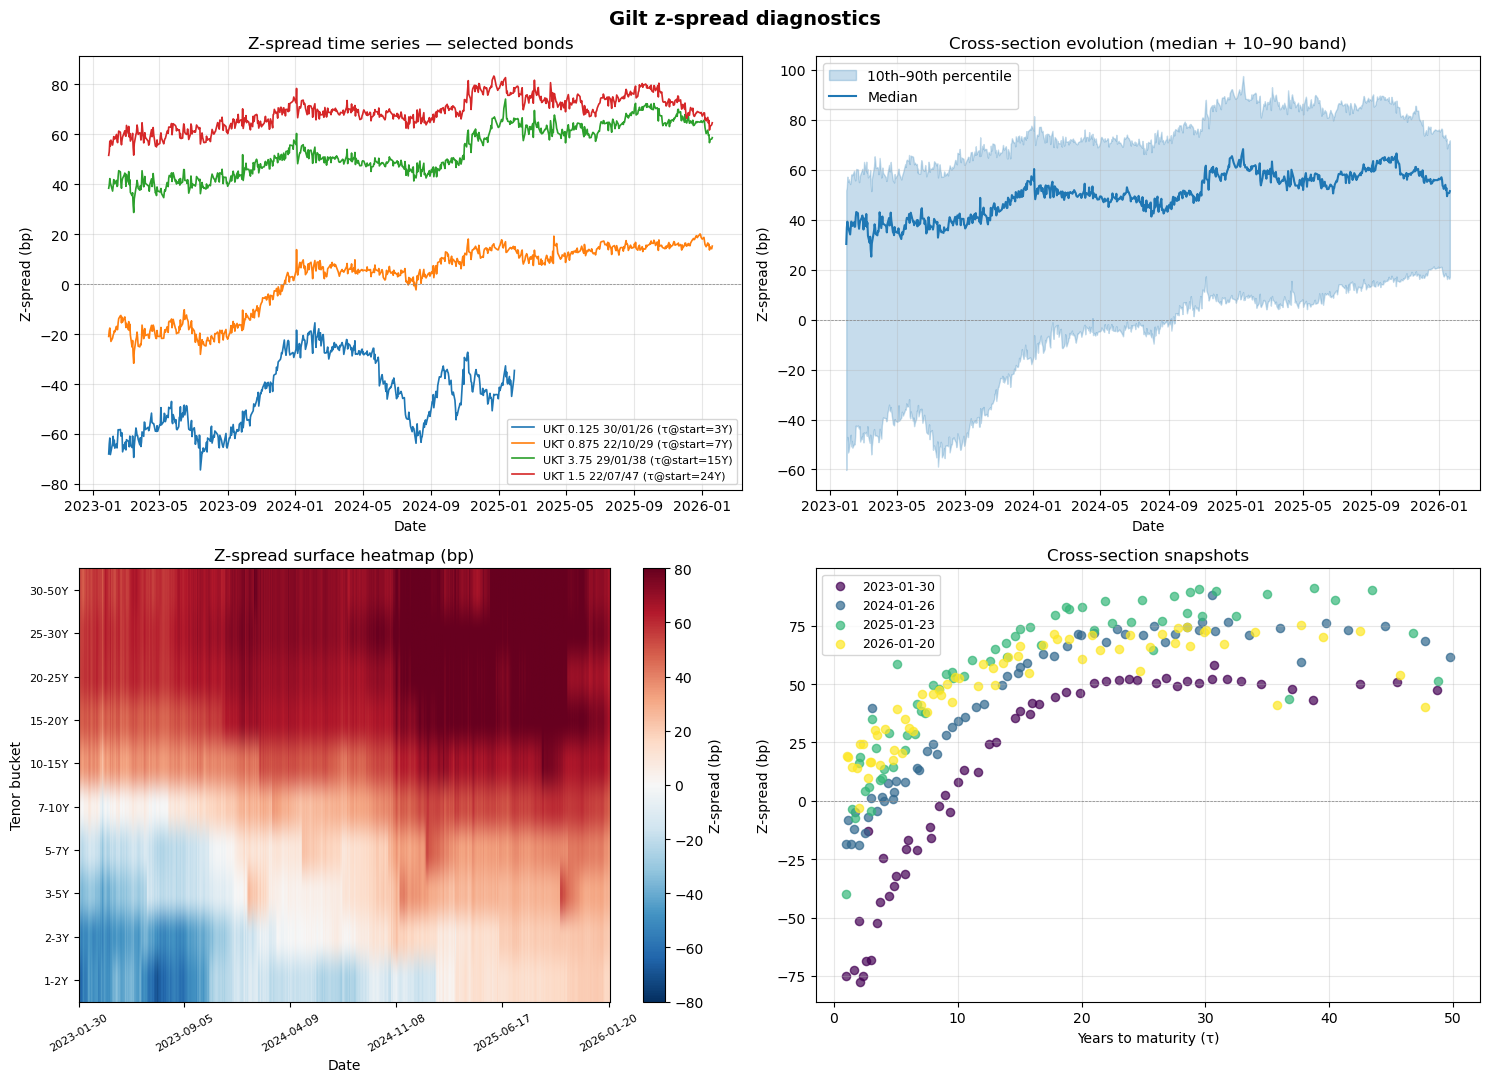

In [33]:
fig = plt.figure(figsize=(15, 11))
 
# (a) Time series of selected bonds
ax = plt.subplot(2, 2, 1)
for isin in chosen:
    series = zb[isin].dropna()
    label = f"{static[isin]['description']} (τ@start={yrs_to_mat(isin, ref_date):.0f}Y)"
    ax.plot(series.index, series.values, lw=1.2, label=label)
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel("Date")
ax.set_ylabel("Z-spread (bp)")
ax.set_title("Z-spread time series — selected bonds")
ax.legend(loc="best", fontsize=8)
ax.grid(alpha=0.3)
 
# (b) Daily cross-section stats: median, 10th, 90th percentile
ax = plt.subplot(2, 2, 2)
med = zb.median(axis=1)
p10 = zb.quantile(0.10, axis=1)
p90 = zb.quantile(0.90, axis=1)
ax.fill_between(med.index, p10, p90, alpha=0.25, color="C0",
                label="10th–90th percentile")
ax.plot(med.index, med, color="C0", lw=1.5, label="Median")
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel("Date")
ax.set_ylabel("Z-spread (bp)")
ax.set_title("Cross-section evolution (median + 10–90 band)")
ax.legend(loc="best")
ax.grid(alpha=0.3)
 
# (c) Heatmap: z-spread surface (date × tenor bucket)
ax = plt.subplot(2, 2, 3)
# For each date, compute average z-spread in tenor buckets
tenor_edges = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 50]
tenor_labels = [f"{tenor_edges[i]}-{tenor_edges[i+1]}Y" for i in range(len(tenor_edges)-1)]
 
heatmap = np.full((len(z_filtered.index), len(tenor_labels)), np.nan)
for di, date in enumerate(z_filtered.index):
    for isin in zb.columns:
        v = zb.loc[date, isin]
        if pd.isna(v):
            continue
        tau = yrs_to_mat(isin, date)
        for bi in range(len(tenor_edges)-1):
            if tenor_edges[bi] <= tau < tenor_edges[bi+1]:
                if np.isnan(heatmap[di, bi]):
                    heatmap[di, bi] = v
                else:
                    heatmap[di, bi] = (heatmap[di, bi] + v) / 2  # avg
                break
 
im = ax.imshow(heatmap.T, aspect="auto", cmap="RdBu_r",
               vmin=-80, vmax=80, origin="lower",
               extent=[0, len(z_filtered.index), 0, len(tenor_labels)])
ax.set_yticks(np.arange(len(tenor_labels)) + 0.5)
ax.set_yticklabels(tenor_labels, fontsize=8)
# Approximate date ticks
n_ticks = 6
tick_positions = np.linspace(0, len(z_filtered.index)-1, n_ticks).astype(int)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(z_filtered.index[i]) for i in tick_positions], rotation=30, fontsize=8)
ax.set_xlabel("Date")
ax.set_ylabel("Tenor bucket")
ax.set_title("Z-spread surface heatmap (bp)")
plt.colorbar(im, ax=ax, label="Z-spread (bp)")
 
# (d) Cross-section snapshots at 4 dates
ax = plt.subplot(2, 2, 4)
n_dates = len(z_filtered.index)
snap_dates = [z_filtered.index[i] for i in [0, n_dates//3, 2*n_dates//3, n_dates-1]]
colors = plt.cm.viridis(np.linspace(0, 1, len(snap_dates)))
 
for date, color in zip(snap_dates, colors):
    xs, ys = [], []
    for isin in zb.columns:
        v = zb.loc[date, isin]
        if pd.isna(v):
            continue
        xs.append(yrs_to_mat(isin, date))
        ys.append(v)
    order = np.argsort(xs)
    xs = np.array(xs)[order]
    ys = np.array(ys)[order]
    ax.scatter(xs, ys, color=color, alpha=0.7, s=35, label=str(date))
 
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel("Years to maturity (τ)")
ax.set_ylabel("Z-spread (bp)")
ax.set_title("Cross-section snapshots")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)
 
plt.suptitle("Gilt z-spread diagnostics", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [34]:
LAMBDA_1 = 1.5 
LAMBDA_2 = 5.0

In [35]:
def nss_basis(tau, l1=LAMBDA_1, l2=LAMBDA_2):

    eps = 1e-8
    tau = np.asarray(tau, dtype=float)
    x1 = np.maximum(tau / l1, eps)
    x2 = np.maximum(tau / l2, eps)
 
    f1 = (1 - np.exp(-x1)) / x1 
    f2 = f1 - np.exp(-x1) 
    f3 = (1 - np.exp(-x2)) / x2 - np.exp(-x2)
 
    X = np.column_stack([np.ones_like(tau), f1, f2, f3])
    return X

In [36]:
def fit_nss_fixed_lambda(taus, zs, l1=LAMBDA_1, l2=LAMBDA_2):
    
    X = nss_basis(taus, l1, l2)
    betas, _, _, _ = np.linalg.lstsq(X, zs, rcond=None)
    fitted = X @ betas
    residuals = zs - fitted
    return betas, fitted, residuals
 
 
def predict_nss(taus, betas, l1=LAMBDA_1, l2=LAMBDA_2):
    
    X = nss_basis(taus, l1, l2)
    return X @ betas

In [37]:
TEST_DATE = dt.date(2023, 1, 30)
 
zb_today = z_filtered.loc[TEST_DATE].dropna()
isins_today = list(zb_today.index)
zs_today  = zb_today.values
taus_today = np.array([(static[i]["maturity_date"] - TEST_DATE).days / 365.25
                       for i in isins_today])
 
betas, fitted, residuals = fit_nss_fixed_lambda(taus_today, zs_today)
 
print(f"Fit on {TEST_DATE} (λ1={LAMBDA_1}, λ2={LAMBDA_2})")
print(f"  β0 (level)        = {betas[0]*1e4:7.2f} bp")
print(f"  β1 (slope)        = {betas[1]*1e4:7.2f} bp")
print(f"  β2 (curvature 1)  = {betas[2]*1e4:7.2f} bp")
print(f"  β3 (curvature 2)  = {betas[3]*1e4:7.2f} bp")
 
residuals_bp = residuals * 1e4
print(f"\nResidual stats (bp):")
print(f"  RMSE   = {np.sqrt(np.mean(residuals_bp**2)):.2f}")
print(f"  max|r| = {np.abs(residuals_bp).max():.2f}")
print(f"  mean   = {residuals_bp.mean():.4f}")

Fit on 2023-01-30 (λ1=1.5, λ2=5.0)
  β0 (level)        =   71.40 bp
  β1 (slope)        = -111.10 bp
  β2 (curvature 1)  = -262.62 bp
  β3 (curvature 2)  =  -10.98 bp

Residual stats (bp):
  RMSE   = 9.69
  max|r| = 47.20
  mean   = -0.0000


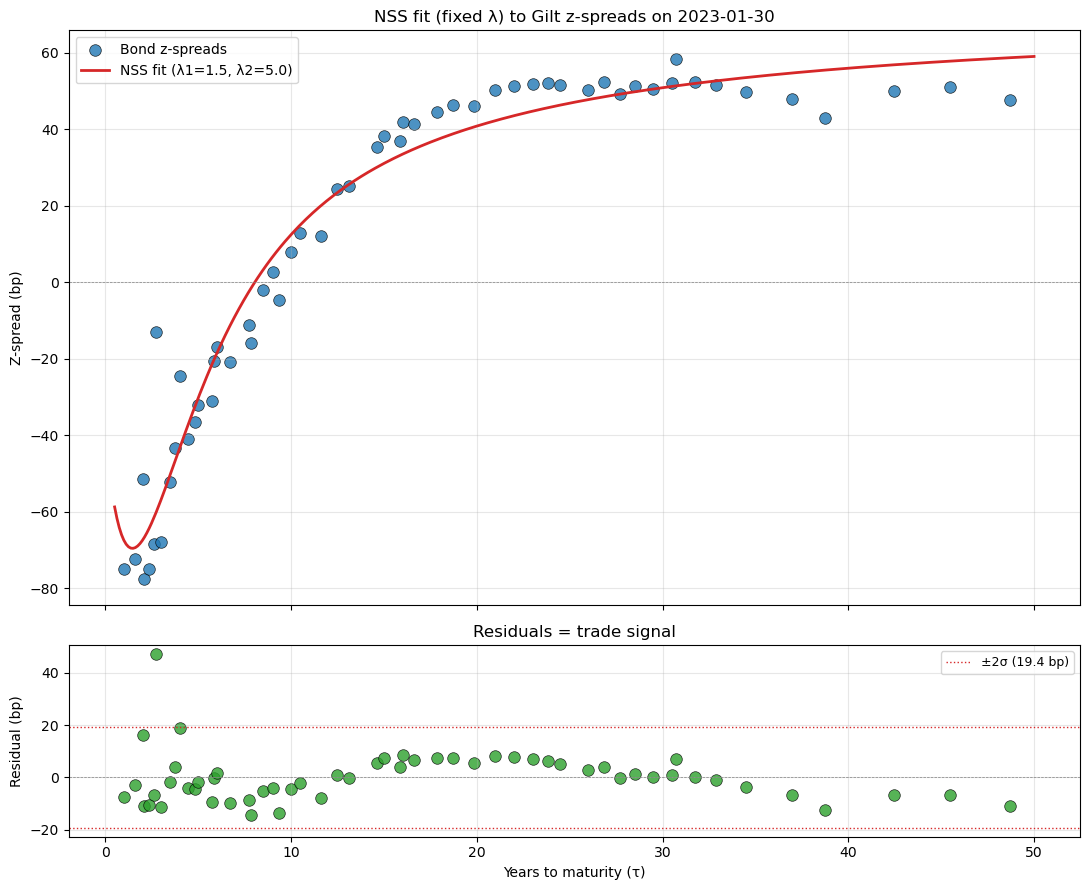


Top 10 outliers:
ISIN           description                      τ    z (bp)   fit (bp)      resid
GB00BPCJD880   UKT 3.5 22/10/25               2.7     -13.1      -60.3     +47.20
GB00BL6C7720   UKT 4.125 29/01/27             4.0     -24.4      -43.4     +19.00
GB00BLPK7110   UKT 0.25 31/01/25              2.0     -51.4      -67.4     +16.02
GB00B24FF097   UKT 4.75 07/12/30              7.9     -15.7       -1.5     -14.28
GB0004893086   UKT 4.25 07/06/32              9.4      -4.6        8.8     -13.47
GB00BMBL1D50   UKT 0.5 22/10/61              38.7      43.1       55.5     -12.45
GB00BL68HJ26   UKT 0.125 30/01/26             3.0     -68.0      -56.8     -11.18
GB00BFMCN652   UKT 1.625 22/10/71            48.7      47.6       58.8     -11.13
GB0030880693   UKT 5 07/03/25                 2.1     -77.6      -66.7     -10.86
GB00BK5CVX03   UKT 0.625 07/06/25             2.4     -75.0      -64.4     -10.61


In [38]:
fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True,
                          gridspec_kw={"height_ratios": [3, 1]})
 
ax = axes[0]
ax.scatter(taus_today, zs_today * 1e4, s=70, edgecolor="k", lw=0.5,
           alpha=0.8, label="Bond z-spreads", color="C0")
tau_grid = np.linspace(0.5, 50, 400)
ax.plot(tau_grid, predict_nss(tau_grid, betas) * 1e4, color="C3", lw=2,
        label=f"NSS fit (λ1={LAMBDA_1}, λ2={LAMBDA_2})")
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_ylabel("Z-spread (bp)")
ax.set_title(f"NSS fit (fixed λ) to Gilt z-spreads on {TEST_DATE}")
ax.legend(loc="best")
ax.grid(alpha=0.3)
 
ax = axes[1]
ax.scatter(taus_today, residuals_bp, s=70, edgecolor="k", lw=0.5,
           alpha=0.8, color="C2")
ax.axhline(0, color="grey", lw=0.5, ls="--")
sigma = residuals_bp.std()
ax.axhline( 2 * sigma, color="C3", ls=":", lw=1, label=f"±2σ ({2*sigma:.1f} bp)")
ax.axhline(-2 * sigma, color="C3", ls=":", lw=1)
ax.set_xlabel("Years to maturity (τ)")
ax.set_ylabel("Residual (bp)")
ax.set_title("Residuals = trade signal")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)
 
plt.tight_layout()
plt.show()
 
 
outlier_idx = np.argsort(np.abs(residuals_bp))[::-1][:10]
print(f"\nTop 10 outliers:")
print(f"{'ISIN':<14} {'description':<28} {'τ':>5}  {'z (bp)':>8}  {'fit (bp)':>9}  {'resid':>9}")
for idx in outlier_idx:
    isin = isins_today[idx]
    info = static[isin]
    print(f"{isin:<14} {info['description']:<28} {taus_today[idx]:>5.1f}  "
          f"{zs_today[idx]*1e4:>8.1f}  {fitted[idx]*1e4:>9.1f}  "
          f"{residuals_bp[idx]:>+9.2f}")

In [39]:
betas_list = []
residuals_rows = {}
rmse_list = []
fit_dates = []

for date in tqdm(sorted(z_filtered.index), desc="NSS fit"):
    row = z_filtered.loc[date].dropna()
    if len(row) < 10:
        continue

    isins_d = list(row.index)
    zs_d    = row.values
    taus_d  = np.array([(static[i]["maturity_date"] - date).days / 365.25
                        for i in isins_d])

    try:
        betas_d, fitted_d, residuals_d = fit_nss_fixed_lambda(taus_d, zs_d)
    except Exception as e:
        continue

    fit_dates.append(date)
    betas_list.append(betas_d)
    rmse_list.append(np.sqrt(np.mean(residuals_d**2)))

    
    residuals_rows[date] = dict(zip(isins_d, residuals_d))


betas_df = pd.DataFrame(
    np.array(betas_list),
    index=fit_dates,
    columns=["b0", "b1", "b2", "b3"],
)
betas_df.index.name = "date"

residuals_df = pd.DataFrame.from_dict(residuals_rows, orient="index")
residuals_df.index.name = "date"
residuals_df = residuals_df.reindex(columns=z_filtered.columns).sort_index()

rmse_series = pd.Series(rmse_list, index=fit_dates, name="rmse")
rmse_series.index.name = "date"

print(f"\nFitted NSS on {len(fit_dates)} dates")
print(f"betas_df.shape     = {betas_df.shape}")
print(f"residuals_df.shape = {residuals_df.shape}")


print("\nBeta summary across history (bp):")
print((betas_df * 1e4).describe().round(1))

print(f"\nRMSE across history (bp):")
print(f"  mean = {rmse_series.mean()*1e4:.2f}")
print(f"  min  = {rmse_series.min()*1e4:.2f}")
print(f"  max  = {rmse_series.max()*1e4:.2f}")


betas_df.to_pickle("/Users/ze/Desktop/nss_betas.pkl")
residuals_df.to_pickle("/Users/ze/Desktop/nss_residuals.pkl")
rmse_series.to_pickle("/Users/ze/Desktop/nss_rmse.pkl")
print("\nSaved nss_betas.pkl, nss_residuals.pkl, nss_rmse.pkl")


NSS fit: 100%|██████████| 752/752 [00:00<00:00, 10330.80it/s]


Fitted NSS on 752 dates
betas_df.shape     = (752, 4)
residuals_df.shape = (752, 79)

Beta summary across history (bp):
          b0     b1     b2     b3
count  752.0  752.0  752.0  752.0
mean    85.8  -61.4 -227.2   -9.9
std      7.5   35.6   71.6   47.7
min     61.9 -152.7 -437.3  -80.7
25%     82.0  -79.7 -266.2  -48.7
50%     86.2  -64.7 -224.1  -28.7
75%     90.4  -31.9 -187.0   34.4
max    105.2   18.1  -42.3  108.1

RMSE across history (bp):
  mean = 9.07
  min  = 5.71
  max  = 13.75

Saved nss_betas.pkl, nss_residuals.pkl, nss_rmse.pkl


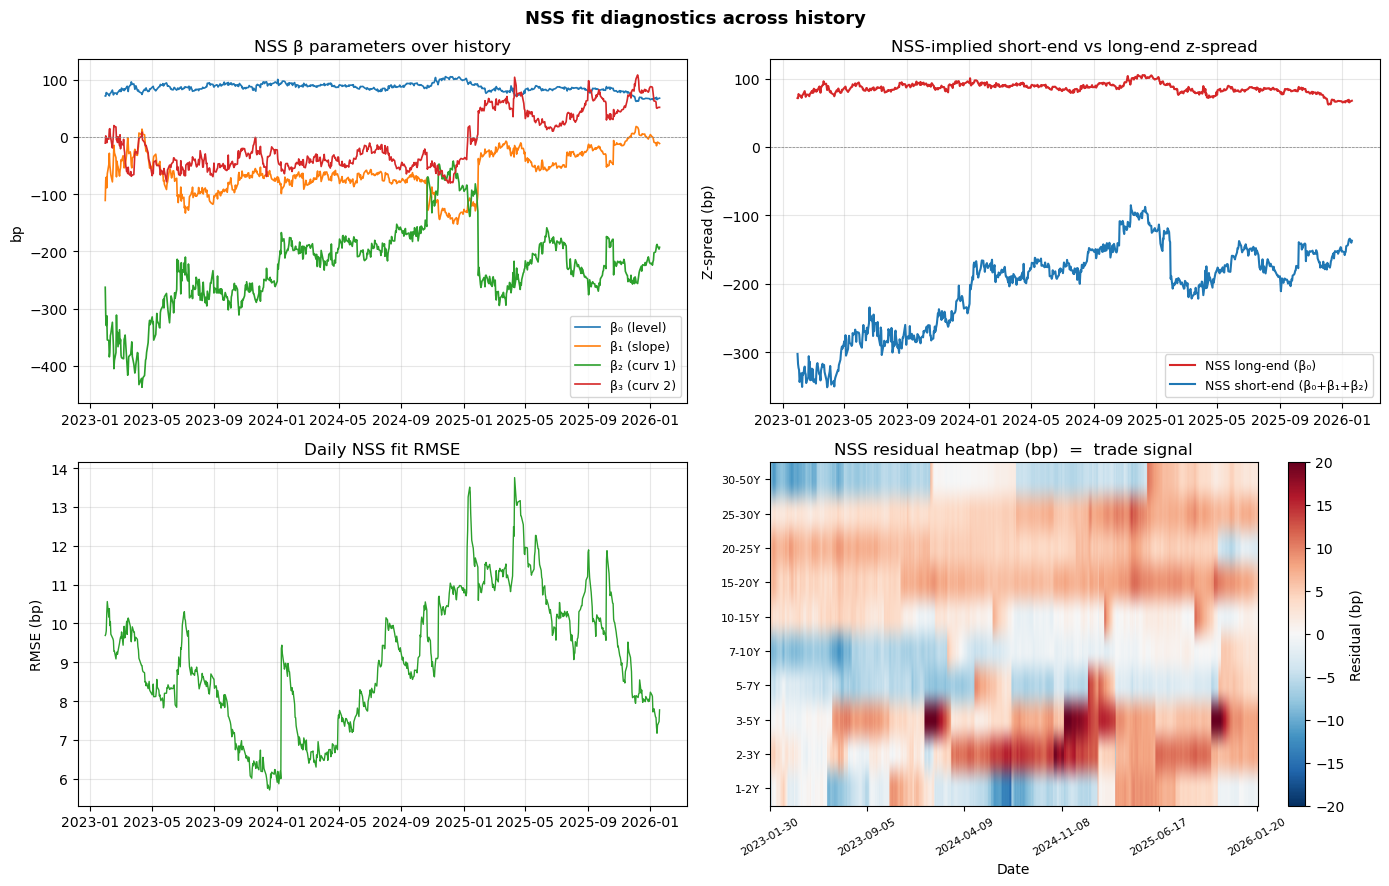


Beta correlations (across history):
      b0    b1    b2    b3
b0  1.00 -0.76  0.43 -0.73
b1 -0.76  1.00 -0.52  0.79
b2  0.43 -0.52  1.00 -0.16
b3 -0.73  0.79 -0.16  1.00


In [40]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# ---- (a) Beta time series ---------------------------------------------
ax = axes[0, 0]
beta_bp = betas_df * 1e4
labels = {"b0": "β₀ (level)", "b1": "β₁ (slope)",
          "b2": "β₂ (curv 1)", "b3": "β₃ (curv 2)"}
for col in betas_df.columns:
    ax.plot(beta_bp.index, beta_bp[col], lw=1.2, label=labels[col])
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_ylabel("bp")
ax.set_title("NSS β parameters over history")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)

# ---- (b) Implied long-term z-spread = β0, short-term = β0+β1+β2 ------
ax = axes[0, 1]
short = (betas_df["b0"] + betas_df["b1"] + betas_df["b2"]) * 1e4
long  = betas_df["b0"] * 1e4
ax.plot(long.index, long,  lw=1.5, label="NSS long-end (β₀)",  color="C3")
ax.plot(short.index, short, lw=1.5, label="NSS short-end (β₀+β₁+β₂)", color="C0")
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_ylabel("Z-spread (bp)")
ax.set_title("NSS-implied short-end vs long-end z-spread")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)

# ---- (c) RMSE time series --------------------------------------------
ax = axes[1, 0]
ax.plot(rmse_series.index, rmse_series * 1e4, lw=1.0, color="C2")
ax.set_ylabel("RMSE (bp)")
ax.set_title("Daily NSS fit RMSE")
ax.grid(alpha=0.3)

# ---- (d) Residual heatmap (date x tenor bucket) ----------------------
ax = axes[1, 1]
tenor_edges  = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 50]
tenor_labels = [f"{tenor_edges[i]}-{tenor_edges[i+1]}Y" for i in range(len(tenor_edges)-1)]
rb = residuals_df * 1e4

heatmap = np.full((len(rb.index), len(tenor_labels)), np.nan)
for di, date in enumerate(rb.index):
    for isin in rb.columns:
        v = rb.loc[date, isin]
        if pd.isna(v):
            continue
        tau = (static[isin]["maturity_date"] - date).days / 365.25
        for bi in range(len(tenor_edges) - 1):
            if tenor_edges[bi] <= tau < tenor_edges[bi+1]:
                if np.isnan(heatmap[di, bi]):
                    heatmap[di, bi] = v
                else:
                    heatmap[di, bi] = (heatmap[di, bi] + v) / 2
                break

im = ax.imshow(heatmap.T, aspect="auto", cmap="RdBu_r",
               vmin=-20, vmax=20, origin="lower",
               extent=[0, len(rb.index), 0, len(tenor_labels)])
ax.set_yticks(np.arange(len(tenor_labels)) + 0.5)
ax.set_yticklabels(tenor_labels, fontsize=8)
n_ticks = 6
tick_positions = np.linspace(0, len(rb.index)-1, n_ticks).astype(int)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(rb.index[i]) for i in tick_positions], rotation=30, fontsize=8)
ax.set_xlabel("Date")
ax.set_title("NSS residual heatmap (bp)  =  trade signal")
plt.colorbar(im, ax=ax, label="Residual (bp)")

plt.suptitle("NSS fit diagnostics across history", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


print("\nBeta correlations (across history):")
print((betas_df).corr().round(2))

Z-score DataFrame shape: (752, 79)
Non-NaN entries: 45,331

Cross-sectional z-score distribution:
  count  : 45,331
  min    : -4.66
  max    : 5.94
  mean   : -0.027  (expect ~0)
  std    : 0.994  (expect ~1)
  |z| > 2: 2,509  (5.5%)


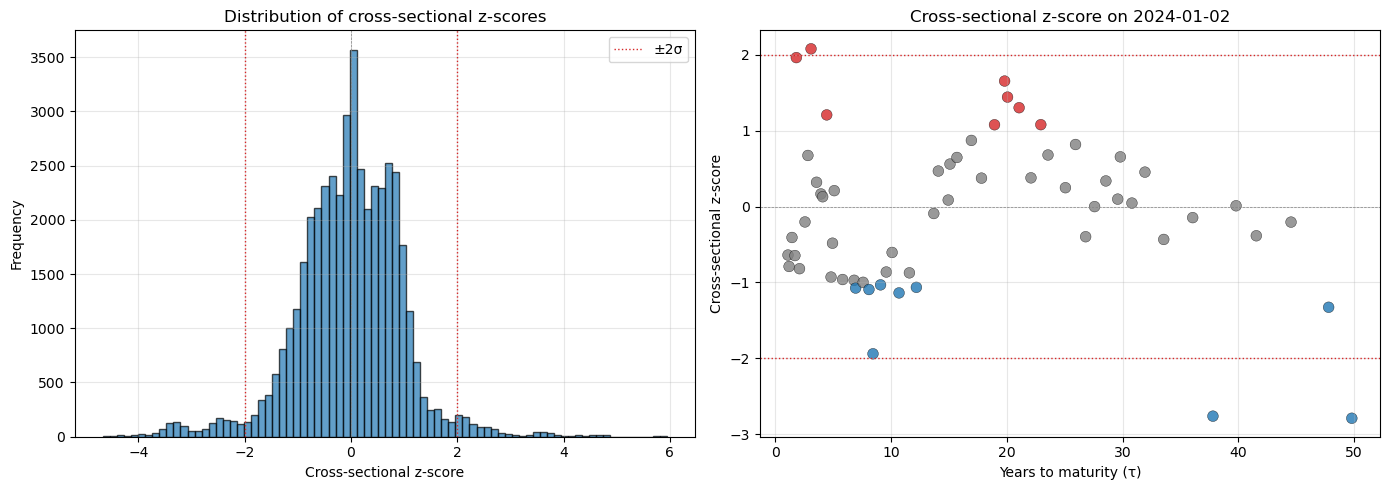

In [41]:
resid_bp  = residuals_df * 1e4
cs_median = resid_bp.median(axis=1)
cs_std    = resid_bp.std(axis=1)
zscore_cs = resid_bp.sub(cs_median, axis=0).div(cs_std, axis=0)

print(f"Z-score DataFrame shape: {zscore_cs.shape}")
print(f"Non-NaN entries: {zscore_cs.notna().sum().sum():,}")

all_z = zscore_cs.values.flatten()
all_z = all_z[~np.isnan(all_z)]
print(f"\nCross-sectional z-score distribution:")
print(f"  count  : {len(all_z):,}")
print(f"  min    : {all_z.min():.2f}")
print(f"  max    : {all_z.max():.2f}")
print(f"  mean   : {all_z.mean():.3f}  (expect ~0)")
print(f"  std    : {all_z.std():.3f}  (expect ~1)")
print(f"  |z| > 2: {(np.abs(all_z) > 2).sum():,}  ({100*(np.abs(all_z)>2).sum()/len(all_z):.1f}%)")

# Visualise distribution + cross-section on one date
TEST_DATE_4a = pd.Timestamp("2024-01-02").date()
if TEST_DATE_4a not in zscore_cs.index:
    TEST_DATE_4a = zscore_cs.index[zscore_cs.index >= TEST_DATE_4a][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.hist(all_z, bins=80, color="C0", edgecolor="k", lw=0.3, alpha=0.7)
ax.axvline(0, color="grey", lw=0.5, ls="--")
ax.axvline(-2, color="C3", lw=1, ls=":", label="±2σ")
ax.axvline( 2, color="C3", lw=1, ls=":")
ax.set_xlabel("Cross-sectional z-score")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of cross-sectional z-scores")
ax.legend(loc="best")
ax.grid(alpha=0.3)

ax = axes[1]
z_today = zscore_cs.loc[TEST_DATE_4a].dropna()
taus_today = np.array([(static[isin]["maturity_date"] - TEST_DATE_4a).days / 365.25
                       for isin in z_today.index])
colors = ['C3' if z > 1 else ('C0' if z < -1 else 'grey') for z in z_today.values]
ax.scatter(taus_today, z_today.values, c=colors, s=60, edgecolor="k", lw=0.3, alpha=0.8)
ax.axhline( 2, color="C3", lw=1, ls=":")
ax.axhline(-2, color="C3", lw=1, ls=":")
ax.axhline(0,  color="grey", lw=0.5, ls="--")
ax.set_xlabel("Years to maturity (τ)")
ax.set_ylabel("Cross-sectional z-score")
ax.set_title(f"Cross-sectional z-score on {TEST_DATE_4a}")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [42]:
TAU_MIN         = 2.0
TAU_MAX         = 30.0
N_PER_SIDE      = 5
ENTRY_FREQ_DAYS = 5
HORIZONS_MONTHS = [3, 6, 12]

In [43]:
def years_to_maturity(isin, date):
    return (static[isin]["maturity_date"] - date).days / 365.25
 
 
def find_exit_date(entry_date, horizon_months, available_dates):
    target = entry_date + dt.timedelta(days=int(horizon_months * 30.44))
    later = [d for d in available_dates if d >= target]
    return min(later) if later else None

In [52]:
def run_trade_resid(entry_date, horizon_months, zscore_cs, residuals_df, static):
    """P&L computed from RESIDUALS, not z-spreads."""
    z_today = zscore_cs.loc[entry_date].dropna()
    resid_today = residuals_df.loc[entry_date]
 
    exit_buffer_days = int(horizon_months * 30.44) + 30
    eligible = []
    for isin, zscore in z_today.items():
        tau = years_to_maturity(isin, entry_date)
        if not (TAU_MIN <= tau <= TAU_MAX):
            continue
        if static[isin]["maturity_date"] < entry_date + dt.timedelta(days=exit_buffer_days):
            continue
        if isin not in resid_today.index or pd.isna(resid_today[isin]):
            continue
        r_entry = resid_today[isin]        # residual (decimal)
        eligible.append((isin, zscore, r_entry, tau))
 
    if len(eligible) < 2 * N_PER_SIDE:
        return None
 
    eligible.sort(key=lambda x: x[1])
    shorts = eligible[:N_PER_SIDE]
    longs  = eligible[-N_PER_SIDE:]
 
    exit_date = find_exit_date(entry_date, horizon_months, residuals_df.index.tolist())
    if exit_date is None:
        return None
 
    pnl_long_bp  = 0.0
    pnl_short_bp = 0.0
    n_long = n_short = 0
 
    for isin, zscore, r_entry, tau in longs:
        r_exit = residuals_df.loc[exit_date, isin] if isin in residuals_df.columns else np.nan
        if pd.isna(r_exit):
            continue
        # Long CHEAP bond: residual is positive (above NSS).
        pnl_long_bp += (r_entry - r_exit) * 1e4
        n_long += 1
 
    for isin, zscore, r_entry, tau in shorts:
        r_exit = residuals_df.loc[exit_date, isin] if isin in residuals_df.columns else np.nan
        if pd.isna(r_exit):
            continue
        # Short RICH bond: residual is negative (below NSS).
        pnl_short_bp += (r_exit - r_entry) * 1e4
        n_short += 1
 
    if n_long < N_PER_SIDE or n_short < N_PER_SIDE:
        return None
 
    return {
        "entry":         entry_date,
        "exit":          exit_date,
        "horizon_m":     horizon_months,
        "pnl_long_bp":   pnl_long_bp / N_PER_SIDE,
        "pnl_short_bp":  pnl_short_bp / N_PER_SIDE,
        "pnl_total_bp":  (pnl_long_bp + pnl_short_bp) / (2 * N_PER_SIDE),
        "long_isins":    [x[0] for x in longs],
        "short_isins":   [x[0] for x in shorts],
    }
 
 

In [53]:
all_dates = sorted(zscore_cs.dropna(how="all").index)
max_entry = all_dates[-1] - dt.timedelta(days=int(max(HORIZONS_MONTHS) * 30.44) + 30)
entry_dates = [d for i, d in enumerate(all_dates)
               if d <= max_entry and i % ENTRY_FREQ_DAYS == 0]
 
results_resid = {h: [] for h in HORIZONS_MONTHS}
for entry_date in entry_dates:
    for h in HORIZONS_MONTHS:
        trade = run_trade_resid(entry_date, h, zscore_cs, residuals_df, static)
        if trade is not None:
            results_resid[h].append(trade)

In [54]:
print("=" * 90)
print("RESIDUAL-BASED P&L  (clean mean-reversion signal)")
print("=" * 90)
print(f"{'Horizon':<10}{'Trades':>8}{'Mean':>10}{'Median':>10}{'Std':>10}"
      f"{'t-stat':>10}{'HitRate':>10}{'LongPnL':>10}{'ShortPnL':>10}")
 
for h in HORIZONS_MONTHS:
    df = pd.DataFrame(results_resid[h])
    pnl = df["pnl_total_bp"].values
    pnl_L = df["pnl_long_bp"].values
    pnl_S = df["pnl_short_bp"].values
    mean  = pnl.mean()
    med   = np.median(pnl)
    std   = pnl.std()
    tstat = mean / (std / np.sqrt(len(pnl))) if std > 0 else 0
    hitrate = (pnl > 0).mean() * 100
    print(f"{h}M{'':<8}{len(df):>8}{mean:>10.2f}{med:>10.2f}{std:>10.2f}"
          f"{tstat:>10.2f}{hitrate:>9.1f}%{pnl_L.mean():>10.2f}{pnl_S.mean():>10.2f}")

RESIDUAL-BASED P&L  (clean mean-reversion signal)
Horizon     Trades      Mean    Median       Std    t-stat   HitRate   LongPnL  ShortPnL
3M              97      1.84      1.54      2.18      8.33     81.4%      2.69      1.00
6M              97      2.52      1.80      3.04      8.17     76.3%      3.69      1.34
12M              97      2.88      1.84      3.52      8.06     80.4%      5.12      0.64


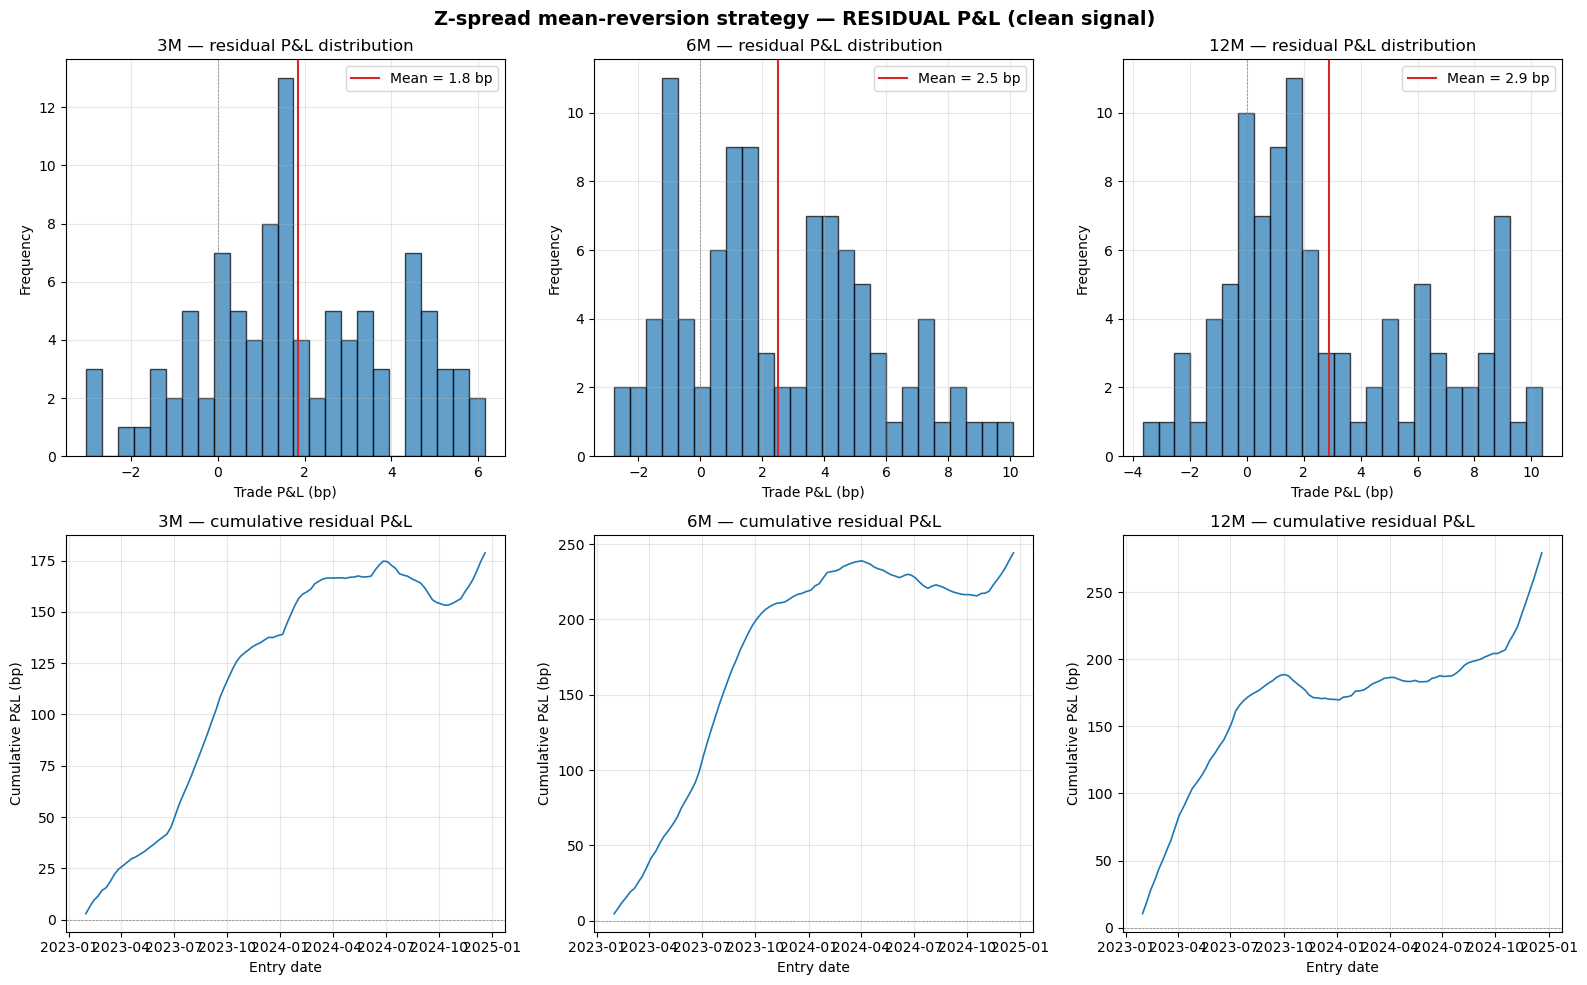

In [55]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
 
for i, h in enumerate(HORIZONS_MONTHS):
    df = pd.DataFrame(results_resid[h])
    pnl = df["pnl_total_bp"].values
 
    ax = axes[0, i]
    ax.hist(pnl, bins=25, color="C0", edgecolor="k", lw=0.3, alpha=0.7)
    ax.axvline(0, color="grey", lw=0.5, ls="--")
    ax.axvline(pnl.mean(), color="C3", lw=1.5, label=f"Mean = {pnl.mean():.1f} bp")
    ax.set_xlabel("Trade P&L (bp)")
    ax.set_ylabel("Frequency")
    ax.set_title(f"{h}M — residual P&L distribution")
    ax.legend()
    ax.grid(alpha=0.3)
 
    ax = axes[1, i]
    entry_dates_h = [t["entry"] for t in results_resid[h]]
    cumpnl = np.cumsum(pnl)
    ax.plot(entry_dates_h, cumpnl, lw=1.2, color="C0")
    ax.axhline(0, color="grey", lw=0.5, ls="--")
    ax.set_xlabel("Entry date")
    ax.set_ylabel("Cumulative P&L (bp)")
    ax.set_title(f"{h}M — cumulative residual P&L")
    ax.grid(alpha=0.3)
 
plt.suptitle("Z-spread mean-reversion strategy — RESIDUAL P&L (clean signal)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [56]:
TRACK_DAYS = [0, 5, 10, 20, 40, 63, 126, 252]
resid_bp = residuals_df * 1e4
 
def event_path(results_list, side, resid_bp):
    
    all_dates = sorted(resid_bp.index)
    paths = []
    for trade in results_list:
        entry_date = trade["entry"]
        if entry_date not in all_dates:
            continue
        entry_idx = all_dates.index(entry_date)
        isins = trade["long_isins"] if side == "long" else trade["short_isins"]
 
        for isin in isins:
            one_path = []
            for dd in TRACK_DAYS:
                if entry_idx + dd >= len(all_dates):
                    one_path.append(np.nan)
                    continue
                d = all_dates[entry_idx + dd]
                v = resid_bp.loc[d, isin] if isin in resid_bp.columns else np.nan
                one_path.append(v)
            paths.append(one_path)
    return np.array(paths)

In [57]:
long_paths  = event_path(results_resid[12], "long",  resid_bp)
short_paths = event_path(results_resid[12], "short", resid_bp)
 
print(f"Long-side paths:  {long_paths.shape}")
print(f"Short-side paths: {short_paths.shape}")
 
# Average across trades (ignore NaN)
long_mean  = np.nanmean(long_paths,  axis=0)
short_mean = np.nanmean(short_paths, axis=0)
long_se    = np.nanstd(long_paths,  axis=0) / np.sqrt(np.sum(~np.isnan(long_paths),  axis=0))
short_se   = np.nanstd(short_paths, axis=0) / np.sqrt(np.sum(~np.isnan(short_paths), axis=0))
 
print(f"\nAvg residual evolution (bp):")
print(f"{'Day':>5} {'Long avg':>10} {'Short avg':>10}")
for dd, la, sa in zip(TRACK_DAYS, long_mean, short_mean):
    print(f"{dd:>5} {la:>10.2f} {sa:>10.2f}")

Long-side paths:  (485, 8)
Short-side paths: (485, 8)

Avg residual evolution (bp):
  Day   Long avg  Short avg
    0      15.07     -10.08
    5      14.74      -9.90
   10      14.45      -9.86
   20      13.92      -9.74
   40      13.11      -9.42
   63      12.32      -9.09
  126      11.28      -8.66
  252       9.97      -9.46


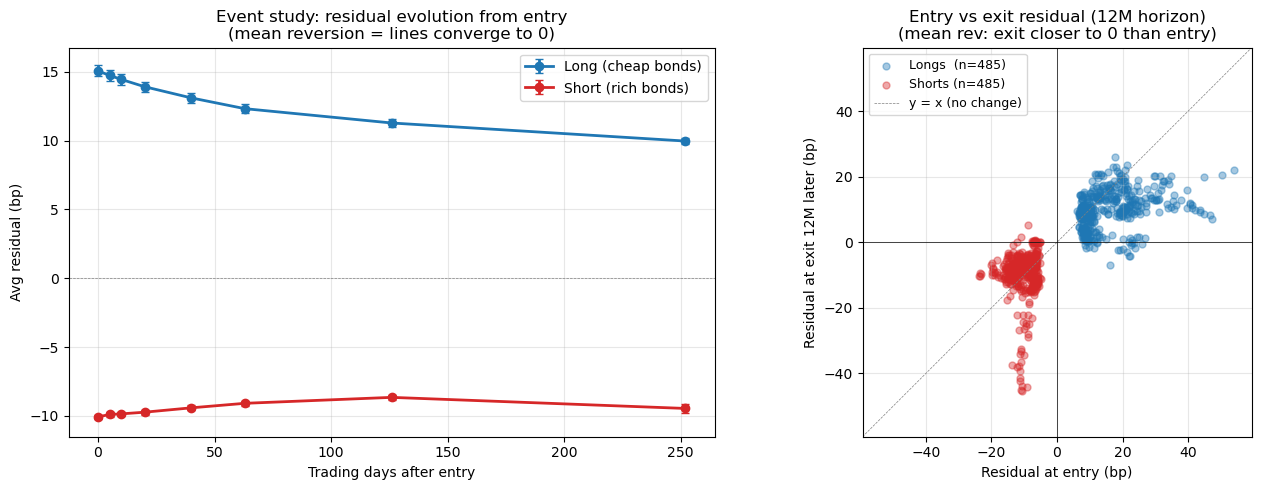

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
# (a) Event study
ax = axes[0]
ax.errorbar(TRACK_DAYS, long_mean,  yerr=long_se,  label="Long (cheap bonds)",
            color="C0", lw=2, marker="o", capsize=3)
ax.errorbar(TRACK_DAYS, short_mean, yerr=short_se, label="Short (rich bonds)",
            color="C3", lw=2, marker="o", capsize=3)
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel("Trading days after entry")
ax.set_ylabel("Avg residual (bp)")
ax.set_title("Event study: residual evolution from entry\n"
             "(mean reversion = lines converge to 0)")
ax.legend(loc="best")
ax.grid(alpha=0.3)
 
# (b) Entry residual vs exit residual (12M trades)
ax = axes[1]
entry_resid = []
exit_resid  = []
for trade in results_resid[12]:
    for isin in trade["long_isins"]:
        e = resid_bp.loc[trade["entry"], isin] if isin in resid_bp.columns else np.nan
        x = resid_bp.loc[trade["exit"],  isin] if isin in resid_bp.columns else np.nan
        if not pd.isna(e) and not pd.isna(x):
            entry_resid.append(e)
            exit_resid.append(x)
long_entries = np.array(entry_resid); long_exits = np.array(exit_resid)
 
entry_resid = []; exit_resid = []
for trade in results_resid[12]:
    for isin in trade["short_isins"]:
        e = resid_bp.loc[trade["entry"], isin] if isin in resid_bp.columns else np.nan
        x = resid_bp.loc[trade["exit"],  isin] if isin in resid_bp.columns else np.nan
        if not pd.isna(e) and not pd.isna(x):
            entry_resid.append(e)
            exit_resid.append(x)
short_entries = np.array(entry_resid); short_exits = np.array(exit_resid)
 
ax.scatter(long_entries,  long_exits,  alpha=0.4, s=25, color="C0",
           label=f"Longs  (n={len(long_entries)})")
ax.scatter(short_entries, short_exits, alpha=0.4, s=25, color="C3",
           label=f"Shorts (n={len(short_entries)})")
# Reference lines
lim = max(abs(long_entries).max(), abs(short_entries).max()) * 1.1
ax.plot([-lim, lim], [-lim, lim], color="grey", lw=0.5, ls="--",
        label="y = x (no change)")
ax.plot([-lim, lim], [0, 0], color="k", lw=0.5)
ax.plot([0, 0], [-lim, lim], color="k", lw=0.5)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("Residual at entry (bp)")
ax.set_ylabel("Residual at exit 12M later (bp)")
ax.set_title("Entry vs exit residual (12M horizon)\n"
             "(mean rev: exit closer to 0 than entry)")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)
ax.set_aspect("equal")
 
plt.tight_layout()
plt.show()

In [59]:
from numpy.polynomial import polynomial as P
 
def simple_slope(x, y):
    x = np.asarray(x); y = np.asarray(y)
    slope, intercept = np.polyfit(x, y, 1)
    return slope, intercept
 
slope_L, _ = simple_slope(long_entries, long_exits)
slope_S, _ = simple_slope(short_entries, short_exits)
 
print(f"\nExit = β · Entry regression (12M horizon):")
print(f"  Longs:   β = {slope_L:.3f}   "
      f"{'(reverting)' if slope_L < 0.9 else '(persistent/trending)' if slope_L > 1.0 else '(random walk)'}")
print(f"  Shorts:  β = {slope_S:.3f}   "
      f"{'(reverting)' if slope_S < 0.9 else '(persistent/trending)' if slope_S > 1.0 else '(random walk)'}")
print(f"\nβ interpretation:")
print(f"  β = 0    perfect mean reversion (full reversion to 0)")
print(f"  β = 0.5  half-life reversion")
print(f"  β = 1    random walk (no reversion, no trending)")
print(f"  β > 1    trending (residuals amplify)")
 


Exit = β · Entry regression (12M horizon):
  Longs:   β = 0.190   (reverting)
  Shorts:  β = 0.155   (reverting)

β interpretation:
  β = 0    perfect mean reversion (full reversion to 0)
  β = 0.5  half-life reversion
  β = 1    random walk (no reversion, no trending)
  β > 1    trending (residuals amplify)


TRANSACTION COST SENSITIVITY  (residual-based P&L, per-bond round-trip cost)
Cost/bond (bp)                      3M                     6M                    12M
                  mean   t-stat   hit%   mean   t-stat   hit%   mean   t-stat   hit%
-----------------------------------------------------------------------------------------------
0.00               1.84   8.33   81.4%     2.52   8.17   76.3%     2.88   8.06   80.4% 
0.25               1.59   7.20   75.3%     2.27   7.36   74.2%     2.63   7.36   74.2% 
0.50               1.34   6.07   72.2%     2.02   6.54   72.2%     2.38   6.66   71.1% 
0.75               1.09   4.94   70.1%     1.77   5.73   68.0%     2.13   5.96   70.1% 
1.00               0.84   3.81   66.0%     1.52   4.92   64.9%     1.88   5.26   63.9% 
1.50               0.34   1.55   51.5%     1.02   3.30   53.6%     1.38   3.86   55.7% 
2.00              -0.16  -0.71   42.3%     0.52   1.68   47.4%     0.88   2.46   46.4% 
3.00              -1.16  -5.23   29.9%   

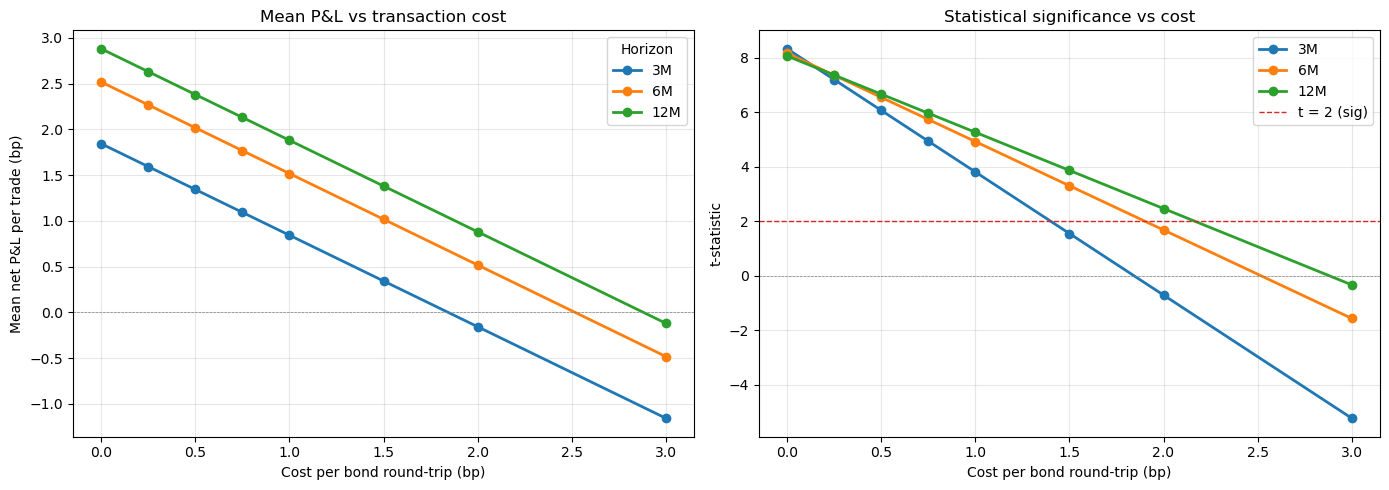


Break-even cost levels (where mean P&L = 0):
   3M horizon:  1.84 bp per bond round-trip
   6M horizon:  2.52 bp per bond round-trip
  12M horizon:  2.88 bp per bond round-trip


In [60]:
COSTS_BP = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]

def apply_cost(pnl_bp, cost_bp_per_bond):
    return pnl_bp - cost_bp_per_bond

pnl_by_h = {h: pd.DataFrame(results_resid[h])["pnl_total_bp"].values
            for h in HORIZONS_MONTHS}

print("=" * 95)
print("TRANSACTION COST SENSITIVITY  (residual-based P&L, per-bond round-trip cost)")
print("=" * 95)
header = f"{'Cost/bond (bp)':<15}"
for h in HORIZONS_MONTHS:
    header += f"{'3M' if h==3 else ('6M' if h==6 else '12M'):>23}"
print(header)
print(f"{'':<15}" + "".join([f"{'mean   t-stat   hit%':>23}" for h in HORIZONS_MONTHS]))
print("-" * 95)

for cost in COSTS_BP:
    row = f"{cost:<15.2f}"
    for h in HORIZONS_MONTHS:
        net = apply_cost(pnl_by_h[h], cost)
        m, s = net.mean(), net.std()
        t = m / (s / np.sqrt(len(net))) if s > 0 else 0
        hit = (net > 0).mean() * 100
        row += f"  {m:>6.2f} {t:>6.2f} {hit:>6.1f}% "
    print(row)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for h in HORIZONS_MONTHS:
    means = [apply_cost(pnl_by_h[h], c).mean() for c in COSTS_BP]
    ax.plot(COSTS_BP, means, marker="o", lw=2, label=f"{h}M")
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel("Cost per bond round-trip (bp)")
ax.set_ylabel("Mean net P&L per trade (bp)")
ax.set_title("Mean P&L vs transaction cost")
ax.legend(title="Horizon"); ax.grid(alpha=0.3)

ax = axes[1]
for h in HORIZONS_MONTHS:
    tstats = []
    for c in COSTS_BP:
        net = apply_cost(pnl_by_h[h], c)
        t = net.mean() / (net.std() / np.sqrt(len(net))) if net.std() > 0 else 0
        tstats.append(t)
    ax.plot(COSTS_BP, tstats, marker="o", lw=2, label=f"{h}M")
ax.axhline(2, color="C3", lw=1, ls="--", label="t = 2 (sig)")
ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel("Cost per bond round-trip (bp)")
ax.set_ylabel("t-statistic")
ax.set_title("Statistical significance vs cost")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("\nBreak-even cost levels (where mean P&L = 0):")
for h in HORIZONS_MONTHS:
    print(f"  {h:2d}M horizon:  {pnl_by_h[h].mean():.2f} bp per bond round-trip")
